# Python walkthrough: from a trained model to calibrated explanations

This page works like a notebook. Each section has a short explanation, the
code, the output that code produced when this page was built, and what the
output means. You can run the same cells yourself: run them in this notebook, or copy the
cells into a Python session.

**One of the [Python tutorials](https://calibrated-explanations-beta.readthedocs.io/en/latest/tutorials/index.html).** Each section follows
the same pattern: a **question**, the code that answers it, the real output,
the concept behind it, and what you can conclude. The same example without
code is [CE by example](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/ce-by-example.html) in the Quick Start.

**Before you start.** You should know what a feature, a label and a
train/test split are, and why CE adds a calibration step; if not, read
[Why CE](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/why-ce.html) first. We use **binary classification**; other tasks are
introduced in [Tasks, modes and capabilities](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/ce-tasks-and-modes.html). No
statistics beyond "probability" and "average" is needed.

**What you will learn**

1. The questions CE answers about one prediction (section 1).
2. Why a model needs three separate data sets (section 2).
3. Why accuracy alone says nothing about probabilities (section 3).
4. Why probabilities need a calibration check (section 4).
5. What CE's calibrated probability and its range are, and what they
   guarantee (section 5).
6. How CE builds an explanation (section 6), and how to read one (section 7).
7. How alternative scenarios relate to the explanation (section 8).
8. What you can and cannot conclude (section 9).

Sections 1–10 form the core path. Regression, guarded explanations and
options for shaping explanations follow as extra sections.

Install the packages once:

```bash
pip install calibrated-explanations scikit-learn matplotlib
```

## 1. The prediction problem and the case we follow

A clinic uses a model to flag tumour samples as *malignant* or *benign*. For
one sample the model says *malignant*. Before anyone acts on that, three
questions matter:

1. **How sure is the model?** Not just which label, but how probable it is,
   and how certain that probability is.
2. **Which measurements drive the prediction?**
3. **What would change it?**

This is an educational example on a public dataset, not clinical decision
support.

CE answers these questions about the **model's behaviour**: calibrated
probabilities with uncertainty, explanations with uncertainty, and
alternative scenarios. It does not diagnose, and it does not tell you what
causes a tumour to be malignant.

We follow one test sample, **case 2**, from raw model output to a calibrated
explanation. First, the data.

## 2. Data and the three data roles

**Question.** What data do we have, and which part may each step use?

We predict whether a breast tumour sample is *malignant* or *benign* from 30
numeric measurements of cell nuclei. The target is one of two labels, so this
is **binary classification**. The dataset ships with scikit-learn and needs no
download.

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X, y = data.data, data.target
feature_names = list(data.feature_names)

print("Samples, features:", X.shape)
for label, name in enumerate(data.target_names):
    print(f"Class {label} = {name}: {int((y == label).sum())} samples")

Samples, features: (569, 30)
Class 0 = malignant: 212 samples
Class 1 = benign: 357 samples


**Interpretation.** There are 569 samples and 30 features. Label `0` means
*malignant* and label `1` means *benign*. Remember this mapping: for binary
classification, CE reports the probability of class `1`, which here is
*benign*.

Now we split the data into three parts, each with one job:

| Set | Used for | Seen by the model during training? |
|---|---|---|
| Proper training set | Fitting the model | Yes |
| Calibration set | Calibrating CE's probabilities and explanations | No |
| Test set | Checking performance and explaining new cases | No |

Calibration measures how the trained model behaves on data it has **not**
seen. If calibration used training data, the model would look more reliable
than it is. Using any of these rows in two roles is a form of **data
leakage**.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_proper, X_cal, y_proper, y_cal = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42
)

print(f"Proper training: {len(X_proper)} samples")
print(f"Calibration:     {len(X_cal)} samples")
print(f"Test:            {len(X_test)} samples")

Proper training: 341 samples
Calibration:     114 samples
Test:            114 samples


**Interpretation.** About 60% of the data trains the model, 20% calibrates it
and 20% is kept for testing. `stratify` keeps the class balance similar in
each part, and `random_state` makes the split reproducible. One way to
picture the calibration set: it is the evidence CE uses to judge the model,
so the uncertainty ranges later on reflect how much evidence there is; 114
cases is a small evidence base.

## 3. Train the model and evaluate it

**Question.** How good is an ordinary model, before CE is involved?

`WrapCalibratedExplainer` wraps an ordinary scikit-learn model. Training
happens with `fit`, exactly as in scikit-learn; nothing CE-specific has
happened yet. We use a random forest as an example, not a recommendation: CE
works with models that provide `fit` and `predict` (and `predict_proba` for
classification).

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from calibrated_explanations import WrapCalibratedExplainer

explainer = WrapCalibratedExplainer(
    RandomForestClassifier(n_estimators=100, random_state=42)
)
explainer.fit(X_proper, y_proper)

y_pred_raw = explainer.predict(X_test, calibrated=False)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_raw):.3f}")

Test accuracy: 0.947


**Interpretation.** About 95% of the predicted labels are correct. Accuracy
counts correct labels; it cannot tell us whether a score of 0.16 means a 16%
chance, or how sure the model is about one particular case. For that we look
at the probabilities themselves.

## 4. Why calibration matters

**Question.** Can we take the model's probabilities at face value?

First we **calibrate**: `calibrate` shows CE the held-out calibration set.
The model itself is not changed. Section 5 explains what calibration does;
here we only use it to keep the model's raw scores and CE's calibrated
probabilities side by side.

In [ ]:
explainer.calibrate(X_cal, y_cal, feature_names=feature_names)

raw = explainer.predict_proba(X_test, calibrated=False)[:, 1]
print("Raw P(benign), cases 0-4:", raw[:5].round(2))
extreme = (raw == 0) | (raw == 1)
print("Cases with raw probability exactly 0 or 1:", int(extreme.sum()), "of", len(raw))
print("Of those, correctly labelled:", int(((raw[extreme] > 0.5) == y_test[extreme]).sum()))

Raw P(benign), cases 0-4: [0.   1.   0.16 0.21 0.  ]
Cases with raw probability exactly 0 or 1: 41 of 114
Of those, correctly labelled: 41


**Interpretation.**

- A random forest's `predict_proba` averages the class proportions in the
  leaves its trees reach. When every tree agrees, the output is exactly 0
  or 1.
- A probability of exactly 0 or 1 claims certainty. A model trained on 341
  cases rarely has grounds for certainty, so outputs like these are a common
  **reason to check** calibration.
- They are **not evidence** that the scores are wrong: on this test set, every
  extreme prediction was correct. Whether probabilities are calibrated can
  only be judged against observed outcomes on held-out data.

A probability is **calibrated** if, among all cases given about 70%, about
70% turn out positive. Calibration does not judge or retrain the model. It
learns, from cases the model never saw, how the model's scores relate to
observed outcomes, and it attaches an uncertainty range.

## 5. How Venn–Abers calibration works, and what its output means

**Question.** What does CE's calibrated probability mean, and what is guaranteed?

For classification, CE calibrates with **Venn–Abers** predictors. For each
new case:

1. Sort the calibration cases by the model's score.
2. Fit the best *increasing* curve from score to observed outcome (isotonic
   regression).
3. Do this twice: once adding the new case as *benign*, once as *malignant*.
4. Read both curves at the new case's score. This gives a lower and an upper
   probability, `low` and `high`.
5. Merge the two into one estimate, `high / (1 − low + high)`, which always
   lies between them.

```{mermaid}
flowchart LR
    S["model score of the new case"] --> A["fit with the case labelled benign"]
    S --> B["fit with the case labelled malignant"]
    A --> H["upper probability (high)"]
    B --> L["lower probability (low)"]
    H --> M["merged estimate, between low and high"]
    L --> M
```

In [ ]:
proba, (low, high) = explainer.predict_proba(X_test[:5], uq_interval=True)
y_pred = explainer.predict(X_test)

print("case  raw    calibrated  range           predicted   true")
for i in range(5):
    print(
        f"{i:>4}  {raw[i]:.2f}   {proba[i, 1]:.3f}       [{low[i]:.3f}, {high[i]:.3f}]  "
        f"{data.target_names[y_pred[i]]:<10}  {data.target_names[y_test[i]]}"
    )
print(f"\nTest accuracy after calibration: {accuracy_score(y_test, y_pred):.3f}")

case  raw    calibrated  range           predicted   true
   0  0.00   0.029       [0.000, 0.029]  malignant   malignant
   1  1.00   0.973       [0.972, 1.000]  benign      benign
   2  0.16   0.286       [0.167, 0.333]  malignant   malignant
   3  0.21   0.324       [0.167, 0.400]  malignant   benign
   4  0.00   0.029       [0.000, 0.029]  malignant   malignant

Test accuracy after calibration: 0.947


**Interpretation: what the numbers are.**

- **A pair, not one number.** Venn–Abers produces two probabilities for each
  case, `low` and `high`, from the two fits in step 3.
- **The guarantee belongs to the pair.** Vovk, Petej and Fedorova (2015)
  show that the member of the pair selected by the *true* label (`high` if the
  case is truly benign, `low` if it is truly malignant) is perfectly
  calibrated. Three limits apply: the result assumes the calibration and test
  cases are exchangeable (roughly: drawn from the same stable process); it is
  a property of the predictor over many cases, not a statement about one case;
  and it cannot be used to pick the calibrated member, because the true label
  is unknown when we predict. *Wording under review by the CE authors.*
- **The merged estimate has no exact guarantee.** CE's single number is a
  practical summary between `low` and `high`; merging gives up the exact
  calibration property.
- **What the range is not.** `[low, high]` is not a confidence interval for an
  unknown "true probability" of the case, and it guarantees nothing about one
  individual case.
- **Width.** The width shows how much the calibration curve depends on the
  unknown label of the new case. One way to picture it: it tends to be wider
  where few calibration cases had similar scores.

Case `3` is misclassified (truly benign) and has the widest range of the
five. That is a useful observation, but one case supports no general claim.

Does calibration make the probabilities score better? We can check one common
score on the test set:

In [ ]:
from sklearn.metrics import brier_score_loss

cal = explainer.predict_proba(X_test)[:, 1]
print(f"Brier score, raw:        {brier_score_loss(y_test, raw):.4f}")
print(f"Brier score, calibrated: {brier_score_loss(y_test, cal):.4f}")

Brier score, raw:        0.0366
Brier score, calibrated: 0.0445


**Interpretation.** The **Brier score** is the mean squared difference between
the predicted probability of *benign* and the outcome (1 if benign, 0 if
not); **lower is better** and 0 is perfect (Brier, 1950). On these 114 test
cases the calibrated probabilities scored *worse* than the raw ones.

- Calibration does not necessarily improve scores such as the Brier score on
  every dataset or test set.
- This comparison does not test the guarantee above: the Brier score is
  computed on CE's merged estimate, which does not carry the exact guarantee,
  and on one small test set.
- Do not read a cause into the difference (for example "the forest was
  already well calibrated"): this page does not test that.

What CE adds is the validity property of the probability pair and an
uncertainty range for every case. The
[semantics reference](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/calibrated_interval_semantics.html)
and [How CE Calibrates](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/calibration_methods.html) give
the full statements and the mathematics.

## 6. How CE builds an explanation

**Question.** Where do the numbers in an explanation come from?

Case 2 is predicted *malignant*. Before reading its explanation, it helps to
know where the numbers come from.

**Scope.** The steps below describe how CE computes a factual explanation in
the version and settings used on this page (binary classification, default
explanation options). They are implementation details, not part of the
definition of a calibrated explanation; other settings or later versions can
differ.

| Step | What CE does here | Depends on (default here) |
|---|---|---|
| 1. Split each feature into two ranges | For each feature, CE finds one split point in the calibration data with a one-split decision tree, trained on the model's *predicted* labels for the calibration cases | discretizer `binaryEntropy`; `condition_source="prediction"` |
| 2. Read off the condition | The case falls on one side of the split, which gives the rule's condition, for example `worst concave points > 0.14` | — |
| 3. Try typical values from the other side | CE takes three typical calibration values from the *other* range (its 25th, 50th and 75th percentiles) and puts each into the case in place of its real value | `sample_percentiles=[25, 50, 75]` |
| 4. Ask the calibrated model again | For each modified case CE gets a calibrated probability, lower bound and upper bound, and averages the three probabilities, the three lower bounds and the three upper bounds separately | — |
| 5. Compute the weight | Weight = the case's calibrated probability − that average. The weight interval runs from the case's probability − the averaged upper bound to the case's probability − the averaged lower bound | — |

**In words:** a weight answers "how different would the calibrated probability
be if this feature took typical values from the other side of the split, with
all other features unchanged?" It compares the model's responses; it is not a
cause.

## 7. The factual explanation of our case

**Question.** Which of case 2's values drive its prediction, and how firmly?

`explain_factual` returns a collection; index it to get one explanation.

In [ ]:
case = 2
factual = explainer.explain_factual(X_test[case:case + 1])
explanation = factual[0]

pred = explanation.prediction
print(f"Calibrated P(benign) = {pred['predict']:.3f}  "
      f"range [{pred['low']:.3f}, {pred['high']:.3f}]")

Calibrated P(benign) = 0.286  range [0.167, 0.333]


In [ ]:
def rule_table(expl, top=6):
    rules = expl.get_rules()
    order = np.argsort(-np.abs(np.asarray(rules["weight"], dtype=float)))[:top]
    print(f"{'feature condition':<34} {'weight':>8}   weight interval")
    for i in order:
        print(f"{rules['rule'][i]:<34} {rules['weight'][i]:+8.3f}   "
              f"[{rules['weight_low'][i]:+.3f}, {rules['weight_high'][i]:+.3f}]")

rule_table(explanation)
weights = np.asarray(explanation.get_rules()["weight"], dtype=float)
print(f"\nSum of all {len(weights)} weights: {weights.sum():+.3f}")

feature condition                    weight   weight interval
worst concave points > 0.14          -0.190   [-0.314, -0.048]
worst area <= 853.50                 +0.143   [+0.119, +0.286]
worst concavity <= 0.35              +0.135   [+0.108, +0.286]
mean concavity > 0.07                -0.048   [-0.114, +0.086]
mean concave points > 0.04           -0.048   [-0.114, +0.086]
worst texture > 23.91                -0.042   [-0.114, +0.108]

Sum of all 17 weights: -0.069


**Interpretation.** Read each line as: *"For this case, `<condition>` holds.
With typical values from the other side of the split instead, the calibrated
probability of benign would be lower (positive weight) or higher (negative
weight) by about `<weight>`."*

- **Sign.** A negative weight means the case's condition pulls the probability
  of *benign* down (towards *malignant*); a positive weight pushes it up.
- **Size.** Larger absolute weights matter more for this prediction.
- **Weight interval.** It comes from the averaged lower and upper bounds in
  step 5. Where an interval spans zero, the averaged bounds do not settle the
  direction of the effect. These intervals are differences of averaged
  Venn–Abers bounds; no guarantee is claimed for them.
- **Weights do not add up to the prediction.** Each weight is computed one
  feature at a time; their sum (printed above) differs from the prediction of 0.286.

The plot shows the same explanation for the eight strongest rules:

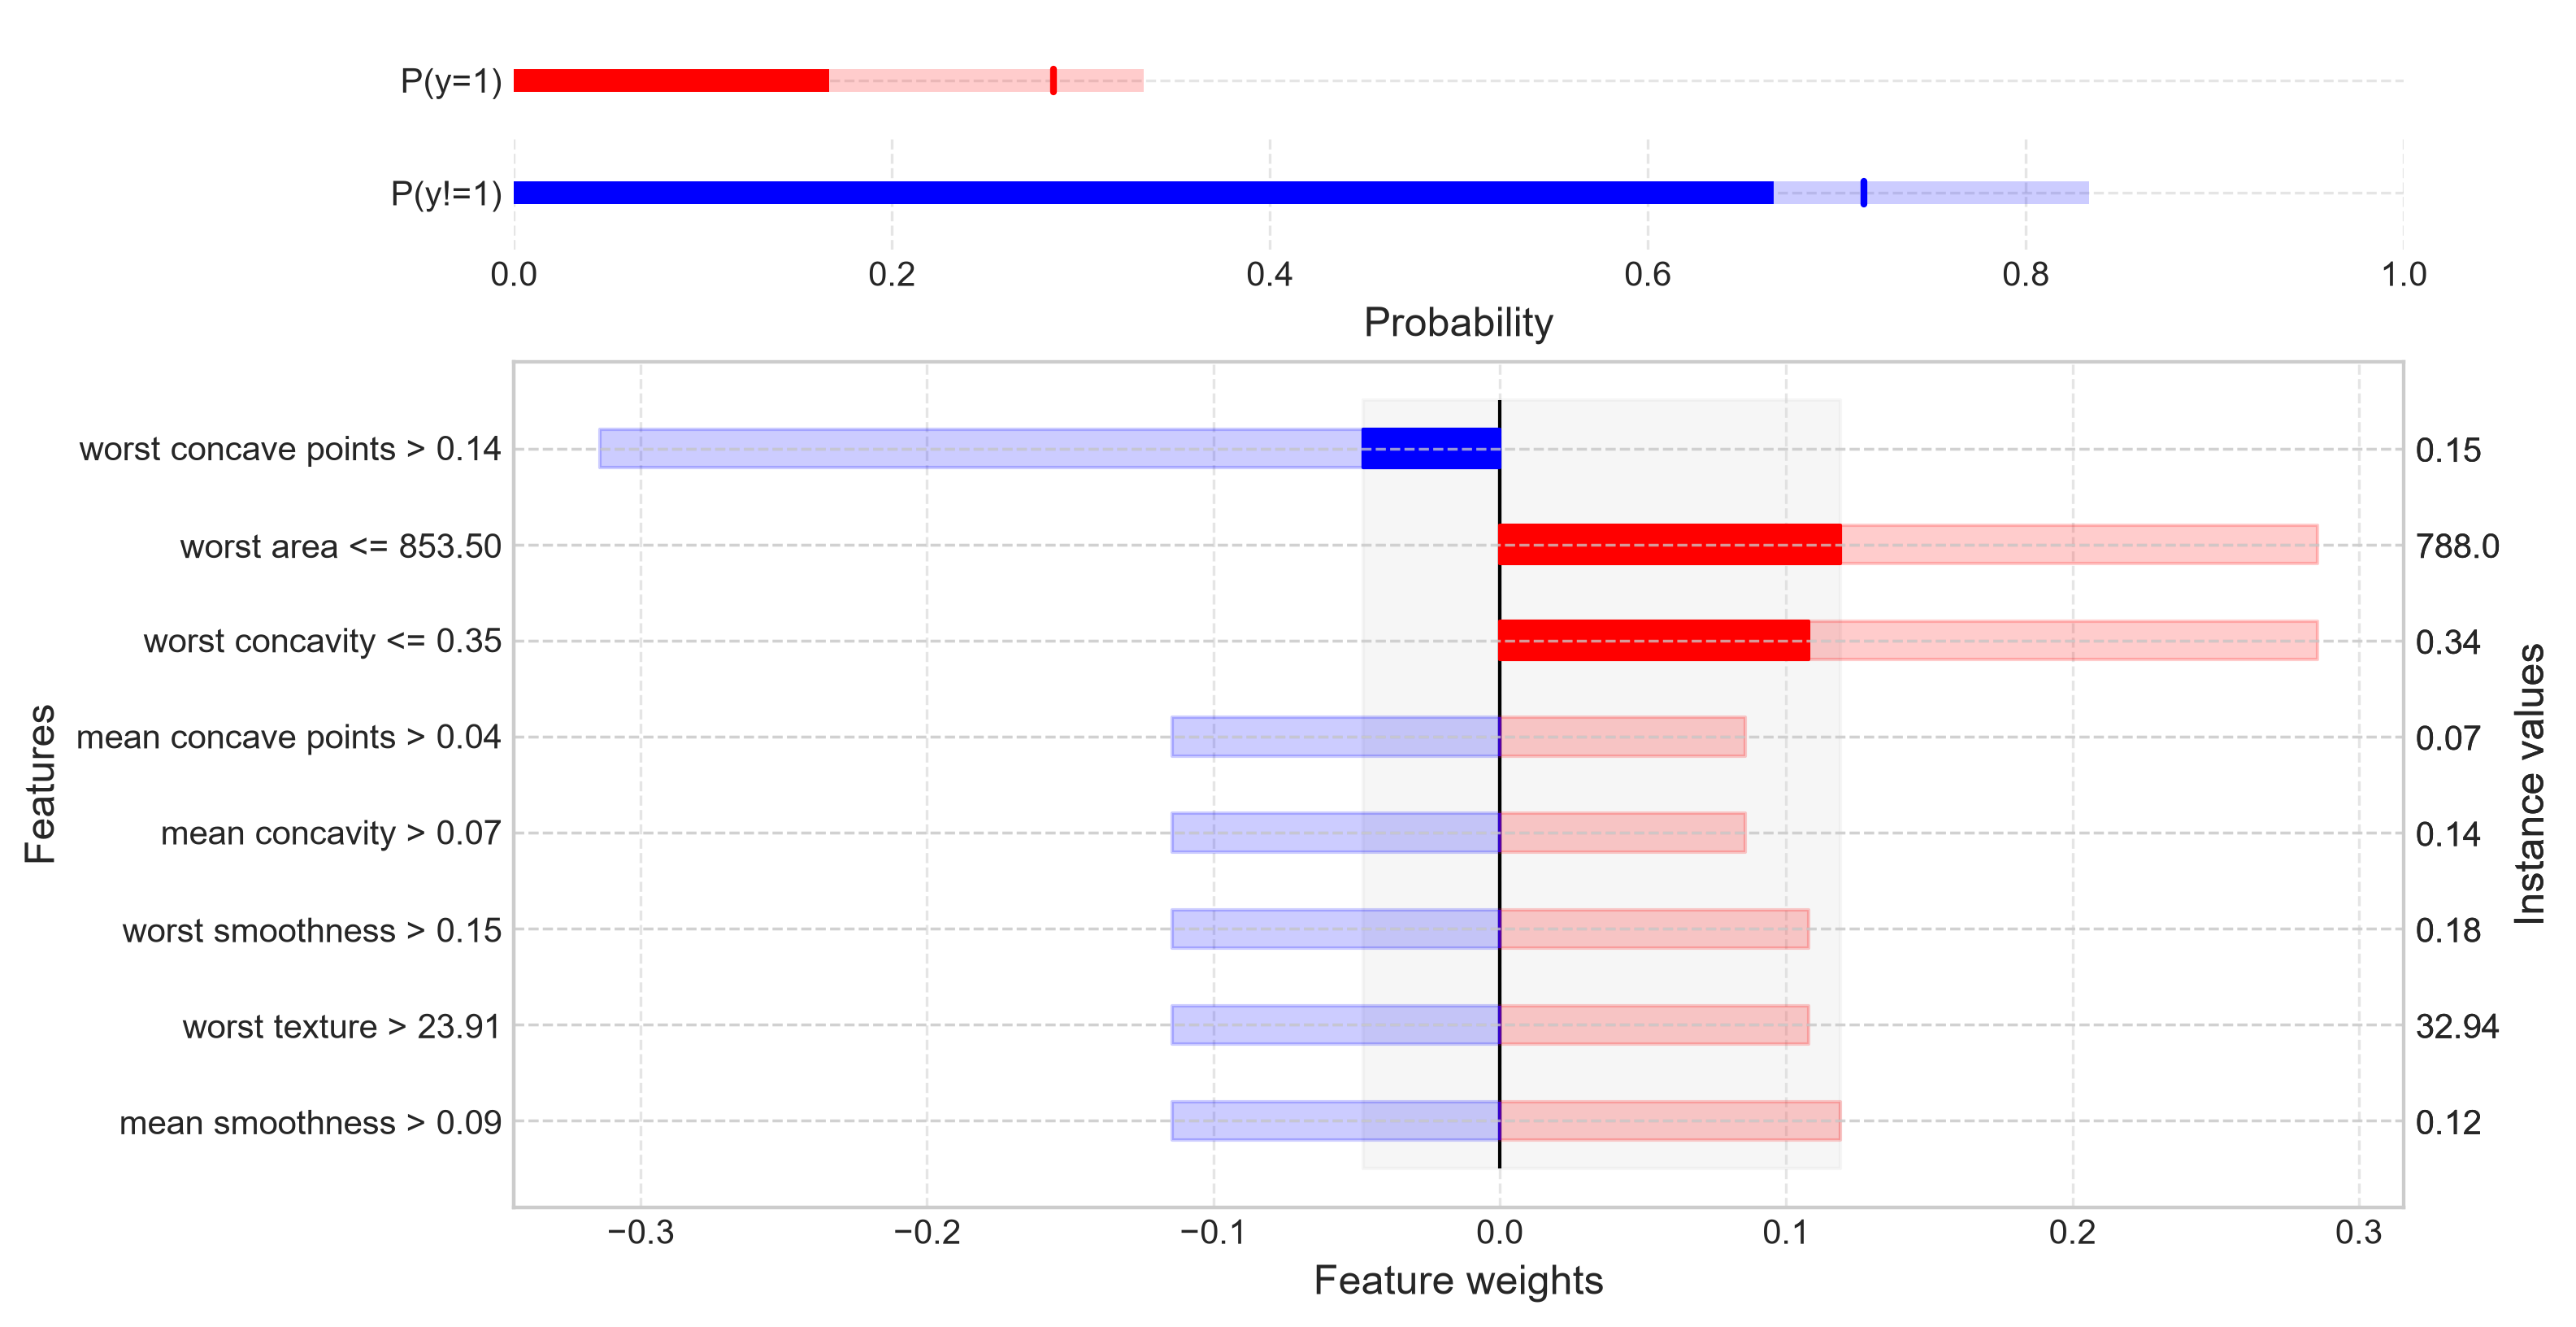

In [ ]:
%matplotlib inline
factual.plot(0, uncertainty=True, filter_top=8)

**Reading the plot.**

- **Top panel.** `P(y=1)` is the probability of *benign*. The vertical line
  marks CE's single estimate; the dark bar runs from 0 to the lower
  probability and the light bar from the lower to the upper probability.
  `P(y!=1)` shows the same for *malignant*.
- **Lower panel.** One row per rule. With the default plot style, rules that
  raise the probability of *benign* are drawn in red and rules that lower it
  in blue.
- The whole bar, light and dark together, is the rule's weight interval. The
  dark part runs from zero to the end of the interval nearest zero; rules
  whose interval crosses zero have no dark part. The point weight itself is
  not drawn: read it from the table above.
- The grey vertical band is this case's own probability range redrawn around
  zero on the weight scale (from 0.286 − 0.333 to 0.286 − 0.167).
- The right-hand axis shows the case's actual feature values.

## 8. Alternative explanations of our case

**Question.** What would the model predict if one feature were different?

An **alternative explanation** asks: *if one feature had a value in a
different range, what would the calibrated prediction be?* Alternatives use
finer ranges than factual rules (up to eight per feature, in either direction).

In [ ]:
alternatives = explainer.explore_alternatives(X_test[case:case + 1])
alt_rules = alternatives[0].get_rules()

base = pred["predict"]
print(f"Current calibrated P(benign): {base:.3f}\n")
print(f"{'alternative condition':<34} {'P(benign)':>9}   range")
order = np.argsort(-np.abs(np.asarray(alt_rules["predict"], dtype=float) - base))[:6]
for i in order:
    print(f"{alt_rules['rule'][i]:<34} {alt_rules['predict'][i]:9.3f}   "
          f"[{alt_rules['predict_low'][i]:.3f}, {alt_rules['predict_high'][i]:.3f}]")

Current calibrated P(benign): 0.286

alternative condition              P(benign)   range
worst concave points < 0.14            0.476   [0.333, 0.600]
worst area > 853.50                    0.143   [0.000, 0.167]
worst concavity > 0.35                 0.151   [0.000, 0.178]
mean concavity < 0.13                  0.333   [0.200, 0.400]
worst area < 745.15                    0.333   [0.200, 0.400]
mean concave points < 0.06             0.333   [0.200, 0.400]


**Interpretation.**

- **The link to the weights.** The first row's probability, 0.476, is the
  average from step 4 behind the strongest factual rule:
  0.286 − 0.476 = −0.190, the weight of `worst concave points > 0.14`.
- **The current prediction.** The calibrated probability of *benign* is 0.286
  with range 0.167 to 0.333. Above 0.5 the predicted label would be *benign*;
  the whole range lies below 0.5, so the model predicts *malignant*.
- **One scenario.** If `worst concave points` were below 0.14, the estimate
  would be 0.476 with range 0.333 to 0.600. The estimate stays below 0.5, but
  the range spans 0.5: in that scenario the calibrated output would no longer
  clearly favour either class. The ranges shown for scenarios are averages of
  Venn–Abers bounds; they do not carry the guarantee from section 5.
- **Direction.** Scenarios can move the probability either way: some rows
  lower it.

Alternatives describe what the **model** would do in a different scenario.
They do not say that changing the tumour would change the diagnosis, and they
do not change how certain the current prediction is.

## 9. What we can and cannot conclude about case 2

**We can say.** The model predicts *malignant*. CE's calibrated probability of
*benign* is 0.29, with a range of 0.17 to 0.33. The prediction depends most
on `worst concave points` being above 0.14: with typical lower values, the
calibrated probability would be about 0.48, and that scenario's range reaches
above 0.5.

**We cannot say:**

- that 0.29 holds for this individual case, or that its "true" probability
  lies between 0.17 and 0.33;
- that the calibrated probabilities score better than the raw ones: on this
  test set they did not (see the Brier scores above);
- that the measurements cause the outcome;
- that the numbers hold for data from a different population, scanner or
  period: the guarantees assume exchangeability;
- that the weight intervals are formal guarantees;
- anything about other cases, from this one case.

## 10. Recap and next steps

- CE answers three questions about one prediction: how sure, which features,
  what would change it.
- Calibration needs its own held-out data; accuracy says nothing about
  probabilities.
- Venn–Abers gives a pair of probabilities whose guarantee holds for the
  pair, under exchangeability; the single number and the range summarise it.
- A factual weight compares the case's calibrated probability with typical
  values from the other side of a split; it is not a cause.
- Alternatives show model behaviour in other scenarios, with their own
  ranges.

**Common mistakes to avoid**

- Calibrating on the training data, or evaluating on the calibration data.
- Reading `[low, high]` as a confidence interval for one case.
- Reading a weight as a cause, or an alternative as a feasible intervention.
- Concluding that calibration improved the model from one small test set.

[Evaluate CE on your own data](https://calibrated-explanations-beta.readthedocs.io/en/latest/practitioner/evaluate_ce.html) covers these
in more depth. The extra sections below show regression, guarded
explanations and ways to shape explanations. The table at the end lists
where to go next.

## Extra 1. The same workflow for regression

The same three steps (`fit`, `calibrate`, `explain`) work for regression; only
the meaning of the output changes.

### Interval regression

For a numeric target, `predict(..., uq_interval=True)` returns a point
prediction and a calibrated prediction interval. By default CE requests the
5th and 95th percentiles, a 90% interval.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor

reg_data = load_diabetes()
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    reg_data.data, reg_data.target, test_size=0.2, random_state=0
)
Xr_proper, Xr_cal, yr_proper, yr_cal = train_test_split(
    Xr_train, yr_train, test_size=0.25, random_state=0
)

regressor = WrapCalibratedExplainer(RandomForestRegressor(random_state=0))
regressor.fit(Xr_proper, yr_proper)
regressor.calibrate(Xr_cal, yr_cal, feature_names=reg_data.feature_names)

point, (lo, hi) = regressor.predict(Xr_test[:3], uq_interval=True)
for p, l, h in zip(point, lo, hi):
    print(f"prediction {p:6.1f}   90% interval [{l:6.1f}, {h:6.1f}]")

prediction  273.4   90% interval [ 186.5,  409.2]
prediction  248.2   90% interval [ 161.2,  384.0]
prediction  172.1   90% interval [  85.2,  308.0]


**Interpretation.** CE builds these intervals with a conformal predictive
system. Under exchangeability, intervals built this way contain the true value
for about 90% of cases *on average*; they do not promise 90% for each
individual case. *Wording under review by the CE authors.*

### Probabilistic (thresholded) regression

Pass a `threshold` to ask for the calibrated probability of an event on the
numeric target. CE returns **P(y ≤ threshold)** in the second column.

In [ ]:
threshold = 150
p_event, (p_lo, p_hi) = regressor.predict_proba(Xr_test[:3], threshold=threshold, uq_interval=True)
for p, l, h in zip(p_event[:, 1], p_lo, p_hi):
    print(f"P(y <= {threshold}) = {p:.3f}   range [{l:.3f}, {h:.3f}]")

P(y <= 150) = 0.077   range [0.000, 0.083]
P(y <= 150) = 0.083   range [0.000, 0.091]
P(y <= 150) = 0.417   range [0.364, 0.455]


**Interpretation.** The first two cases have point predictions far above 150,
so the calibrated probability of an outcome at or below 150 is low. The third
sits closer to the threshold, and its probability is correspondingly higher.
The task is still regression; only the question asked of it changes.

## Extra 2. Guarded explanations

Guarded explanations filter candidate feature ranges through an
in-distribution check, so explanations avoid substituted values that are
unusual relative to the calibration data. They use the same calls with
`guarded_options` (experimental):

In [ ]:
from calibrated_explanations.explanations.guarded_options import GuardedOptions

guarded = explainer.explain_factual(
    X_test[case:case + 1], guarded_options=GuardedOptions(confidence=0.9)
)
summary = guarded.get_guarded_audit()["summary"]
print(f"Candidate intervals tested:   {summary['intervals_tested']}")
print(f"Passed the guard:             {summary['intervals_conforming']}")
print(f"Removed by the guard:         {summary['intervals_removed_guard']}")

Candidate intervals tested:   189
Passed the guard:             183
Removed by the guard:         6


**Interpretation.** The audit shows how many candidate feature ranges the
guard tested and how many it removed. Removed candidates never appear in the
explanation. The guard is a filter, not a certificate: it checks whether each
substituted value is plausible, not whether the case itself is out of
distribution. See the [guarded explanations concept page](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/guarded_explanations.html).

## Extra 3. Shaping explanations

You can exclude features that are not meaningful to the reader, with
`features_to_ignore` (feature indices). Here we exclude the strongest
feature from section 7 and look at the re-ranked rules:

In [ ]:
ignore = [feature_names.index("worst concave points")]
constrained = explainer.explain_factual(X_test[case:case + 1], features_to_ignore=ignore)

shown = constrained[0].get_rules()["rule"]
print("Any rule on the ignored feature?",
      any(r.startswith("worst concave points ") for r in shown))
rule_table(constrained[0], top=4)

Any rule on the ignored feature? False
feature condition                    weight   weight interval
worst area <= 853.50                 +0.143   [+0.119, +0.286]
worst concavity <= 0.35              +0.135   [+0.108, +0.286]
mean concavity > 0.07                -0.048   [-0.114, +0.086]
mean concave points > 0.04           -0.048   [-0.114, +0.086]


**Interpretation.** The ignored feature no longer appears, and the remaining
rules keep their own weights. Excluding a feature changes what is shown, not
the model or its prediction.

You can also add **conjunctions** (rules that combine two conditions, joined
with `&`) with `add_conjunctions()`. Conjunctive weights are computed
differently from single-rule weights: compare conjunctions with each other,
not with single rules. *How to read them is under review by the CE authors.*

### Where to go next

| You want to | Go to |
|---|---|
| Understand calibration and uncertainty properly | [Calibrated interval semantics](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/calibrated_interval_semantics.html) |
| Read explanations in more depth | [Interpret calibrated explanations](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/how-to/interpret_explanations.html) |
| Learn more about alternatives | [Alternative explanations](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/alternatives.html) |
| Go deeper on threshold regression | [Probabilistic regression](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/probabilistic_regression.html) |
| Use guarded explanations | [Guarded explanations tutorial](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/quickstart_guarded.html) |
| Look up method signatures | [Quick API](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/quick_api.html) |
| See how CE calibrates its outputs | [How CE Calibrates](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/calibration_methods.html) |
| See the whole workflow and a learning path | [The CE workflow](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/concepts/ce_workflow.html) |
| Use CE with your own models and pipelines | [Integrate with pipelines](https://calibrated-explanations-beta.readthedocs.io/en/latest/foundations/how-to/integrate_with_pipelines.html) |
| Read this example again without code | [CE by example](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/ce-by-example.html) |
| Find the other Python tutorials | [Python tutorials](https://calibrated-explanations-beta.readthedocs.io/en/latest/tutorials/index.html) |
| Choose a task and mode for your problem | [Tasks, modes and capabilities](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/ce-tasks-and-modes.html) |
| Apply CE to your own data | [Apply CE to your own data](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/apply-to-your-data.html) |
| Install, configure and integrate CE | [CE Software & Integration](https://calibrated-explanations-beta.readthedocs.io/en/latest/sections/software-integration.html) |
| Fix installation problems | [Troubleshooting](https://calibrated-explanations-beta.readthedocs.io/en/latest/get-started/troubleshooting.html) |